# BMED318 Medical Image Processing: Hands-On for Image Reconstruction 

## Goal : To implement the filtered back-projection algorithm to get a reconstructed image
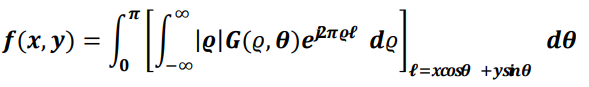

In [1]:
%load_ext autoreload
%autoreload 2

### 1. Make the codes for FBP image reconstruction.

① Read the input file, sinogram.bmp. This sinogram was acquired by PET scan from 0° to 180° of ratation (0 ≤ θ < π).

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from skimage import io


In [3]:

sinogram = io.imread("sinogram.bmp")
sinogram = np.asarray(sinogram, dtype=float)

print("Shape:", sinogram.shape)
print("Data type:", sinogram.dtype)


Shape: (180, 185)
Data type: float64


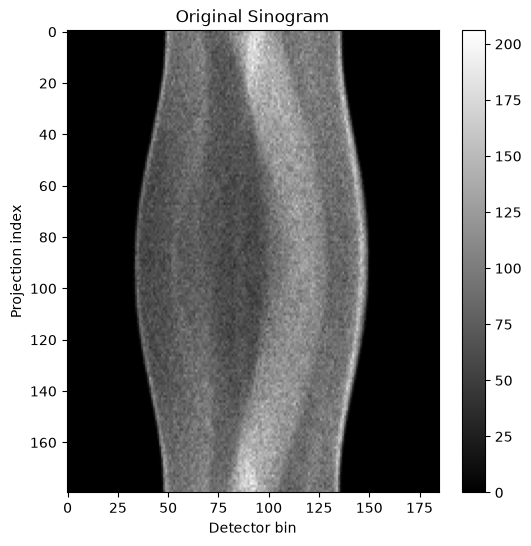

In [4]:

plt.figure(figsize=(6, 6))

plt.imshow(sinogram, cmap="gray", aspect="auto")

plt.title("Original Sinogram")
plt.xlabel("Detector bin")
plt.ylabel("Projection index")

plt.colorbar()
plt.show()


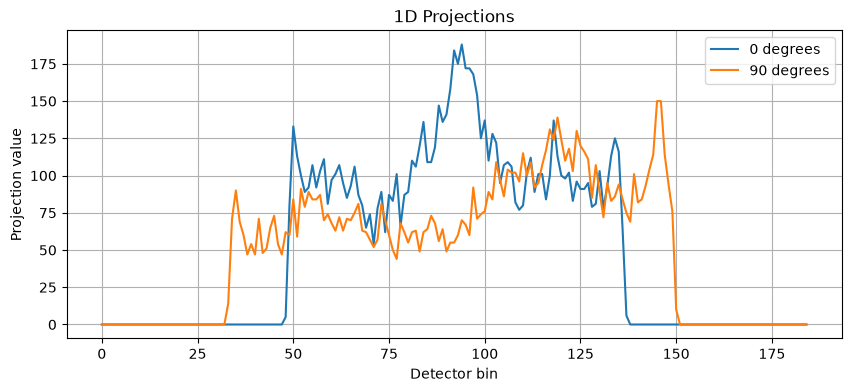

In [5]:
# 한 각도의 projection만 꺼내보기

projection_0 = sinogram[0, :]
projection_90 = sinogram[90, :]

plt.figure(figsize=(10, 4))

plt.plot(projection_0, label="0 degrees")
plt.plot(projection_90, label="90 degrees")

plt.xlabel("Detector bin")
plt.ylabel("Projection value")
plt.title("1D Projections")
plt.legend()
plt.grid(True)
plt.show()


② Frequency Filtering: Generate the ramp filter (||) in the frequency domain. For 0 ≤ θ < π, apply it to the 1D projection (, )|,… in the given 2D sinogram (, ). 
(hint - Ch.7 Freq Filter의 hands-on 중 Frequency Domain Filtering 참고. 즉, 1D 신호
(projection)에 대해 frequency domain filtering을 수행하면 됨)


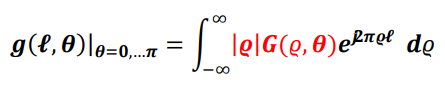

Number of detectors: 185
FFT length: 512
Filter shape: (512,)


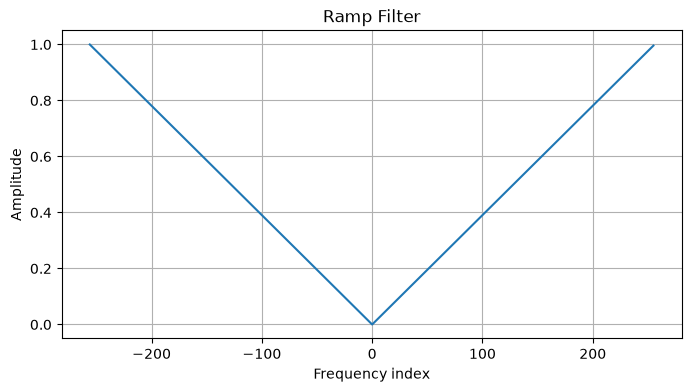

In [6]:

num_angles, num_detectors = sinogram.shape

# Zero-padding을 위한 FFT 길이
fft_length = 2 ** int(np.ceil(np.log2(2 * num_detectors - 1)))

# 주파수 인덱스 생성
freq_bins = np.fft.fftshift(
    np.fft.fftfreq(fft_length)
) * fft_length

nyquist_index = fft_length / 2.0

# Ramp filter
H = np.abs(freq_bins) / nyquist_index

print("Number of detectors:", num_detectors)
print("FFT length:", fft_length)
print("Filter shape:", H.shape)

plt.figure(figsize=(8, 4))
plt.plot(freq_bins, H)
plt.xlabel("Frequency index")
plt.ylabel("Amplitude")
plt.title("Ramp Filter")
plt.grid(True)
plt.show()


③ Backprojection: For 0 ≤ θ < π , generate the backprojected image (, ) at each  from 
the filtered sinogram by implementing
(, )|,…, = (, )|,…,  = (   +    , )|,…,.

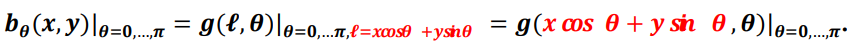

 Explain how you chose the reconstructed image size. (Python package에서 제공되는 iradon 
function을 바로 사용하지 마시오. Backprojection의 원리를 생각해서 구현해보시오. hint: 
rotation() 사용)

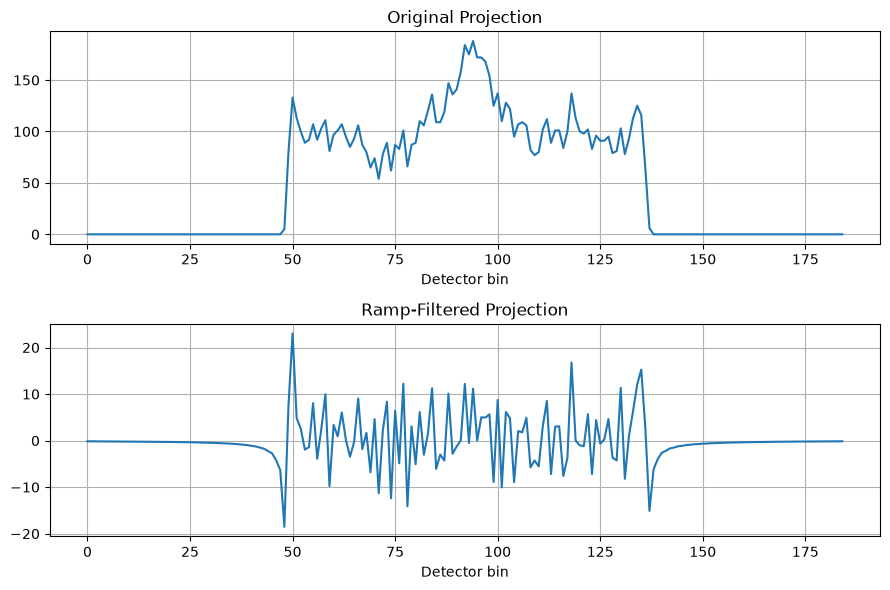

In [7]:

# 0도 projection 추출
projection_1d = sinogram[0, :]

# Zero-padding
padded_projection = np.pad(
    projection_1d,
    (0, fft_length - projection_1d.size),
    mode="constant"
)

# FFT + shift
projection_fft = np.fft.fft(padded_projection)
shifted_fft = np.fft.fftshift(projection_fft)

# Ramp filtering
filtered_fft = shifted_fft * H

# Inverse FFT
unshifted_fft = np.fft.ifftshift(filtered_fft)
filtered_padded = np.real(np.fft.ifft(unshifted_fft))

# 원래 길이로 복원
filtered_projection_1d = filtered_padded[:projection_1d.size]

# 결과 비교
fig, axes = plt.subplots(2, 1, figsize=(9, 6))

axes[0].plot(projection_1d)
axes[0].set_title("Original Projection")

axes[1].plot(filtered_projection_1d)
axes[1].set_title("Ramp-Filtered Projection")

for ax in axes:
    ax.set_xlabel("Detector bin")
    ax.grid(True)

plt.tight_layout()
plt.show()


④ Superposition: For 0 ≤ θ < π , accumulate the image (, )|,…, to make the final 
reconstructed image

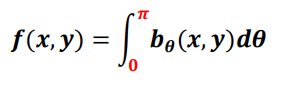

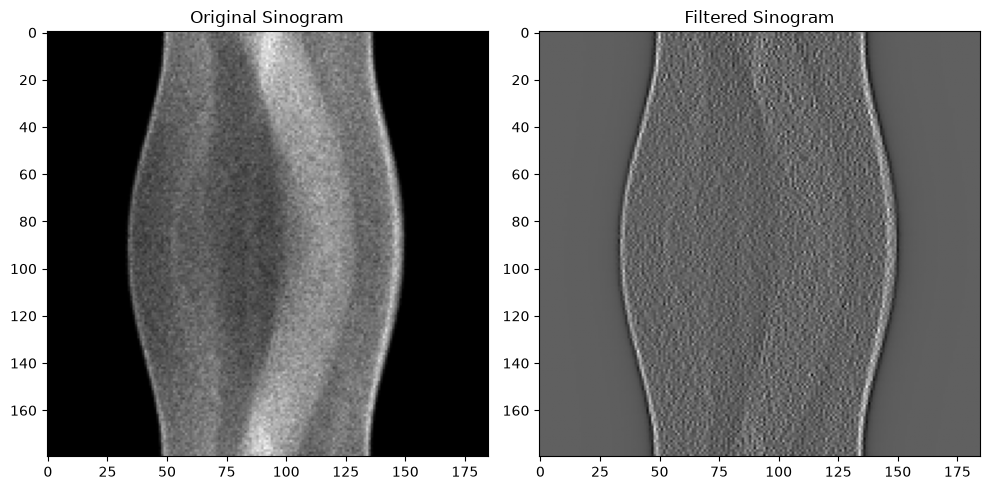

In [8]:

filtered_sinogram = np.zeros_like(sinogram, dtype=float)

for angle_idx in range(num_angles):
    projection_1d = sinogram[angle_idx, :]

    padded = np.pad(
        projection_1d,
        (0, fft_length - num_detectors),
        mode="constant"
    )

    F = np.fft.fftshift(np.fft.fft(padded))
    filtered = np.real(
        np.fft.ifft(np.fft.ifftshift(F * H))
    )

    filtered_sinogram[angle_idx, :] = filtered[:num_detectors]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(sinogram, cmap="gray", aspect="auto")
axes[0].set_title("Original Sinogram")

axes[1].imshow(filtered_sinogram, cmap="gray", aspect="auto")
axes[1].set_title("Filtered Sinogram")

plt.tight_layout()
plt.show()


## 2. Make functions for Prob-1-○2 ,○3 ,○4 respectively. For now, replace the ramp filter with the bandpass filter below (ramp followed by butterworth LPF). Try different cutoff frequencies () to get the best quality in your subjective observation. Describe the reason why you chose those cutoff frequencies. Compare the results with ramp filter. Discuss the results in terms of how the filter impact the quality of reconstructed image.

(hint: 아래 식에서 n 값은 실험해보고 적당한 값으로 지정(일단 2부터). 
 값은 최대 주파수 인덱스의 비율(0.1- 1.0)에 따라 지정하면 편리함. 최대 주파수 인덱스는 sinogram의 한 projection의 길이의 반으로 지정)

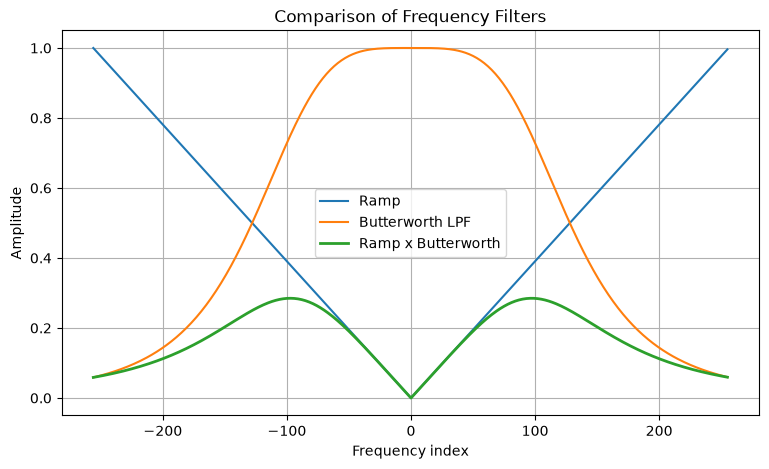

In [9]:

import numpy as np
import matplotlib.pyplot as plt

fft_length = 512
freq_bins = np.fft.fftshift(
    np.fft.fftfreq(fft_length)
) * fft_length

nyquist_index = fft_length / 2.0
ramp = np.abs(freq_bins) / nyquist_index

cutoff_ratio = 0.5
order = 2

cutoff = nyquist_index * cutoff_ratio

butterworth_lpf = 1 / (
    1 + (np.abs(freq_bins) / cutoff) ** (2 * order)
)

H = ramp * butterworth_lpf

plt.figure(figsize=(9, 5))
plt.plot(freq_bins, ramp, label="Ramp")
plt.plot(freq_bins, butterworth_lpf, label="Butterworth LPF")
plt.plot(freq_bins, H, label="Ramp x Butterworth", linewidth=2)

plt.xlabel("Frequency index")
plt.ylabel("Amplitude")
plt.title("Comparison of Frequency Filters")
plt.legend()
plt.grid(True)
plt.show()


## 비교실험

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[Rotation example]
Original FOV:        (9, 9)
reshape=False:      (9, 9)
reshape=True:       (13, 13)


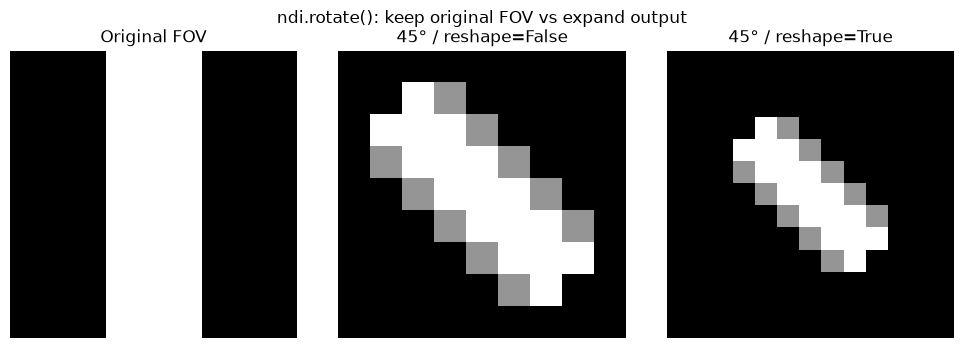

In [10]:
%load_ext autoreload
%autoreload 2

from Week09_FBP_skeleton import reconstruct_fbp

Number of projections (angles): 180
Number of detector bins:        185


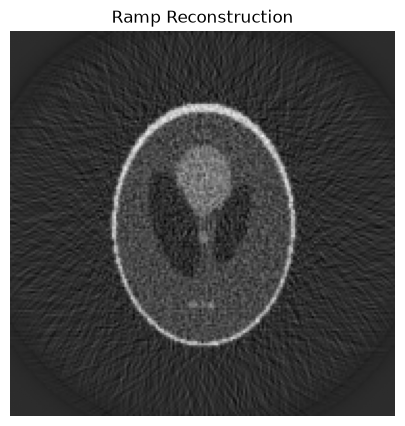

In [11]:
_, _, _, recon_ramp = reconstruct_fbp(
    sinogram,
    filter_type="ramp"
)

plt.figure(figsize=(5, 5))
plt.imshow(recon_ramp, cmap="gray")
plt.title("Ramp Reconstruction")
plt.axis("off")
plt.show()

## CUTOFF 비교실험

Number of projections (angles): 180
Number of detector bins:        185
Number of projections (angles): 180
Number of detector bins:        185
Number of projections (angles): 180
Number of detector bins:        185
Number of projections (angles): 180
Number of detector bins:        185
Number of projections (angles): 180
Number of detector bins:        185


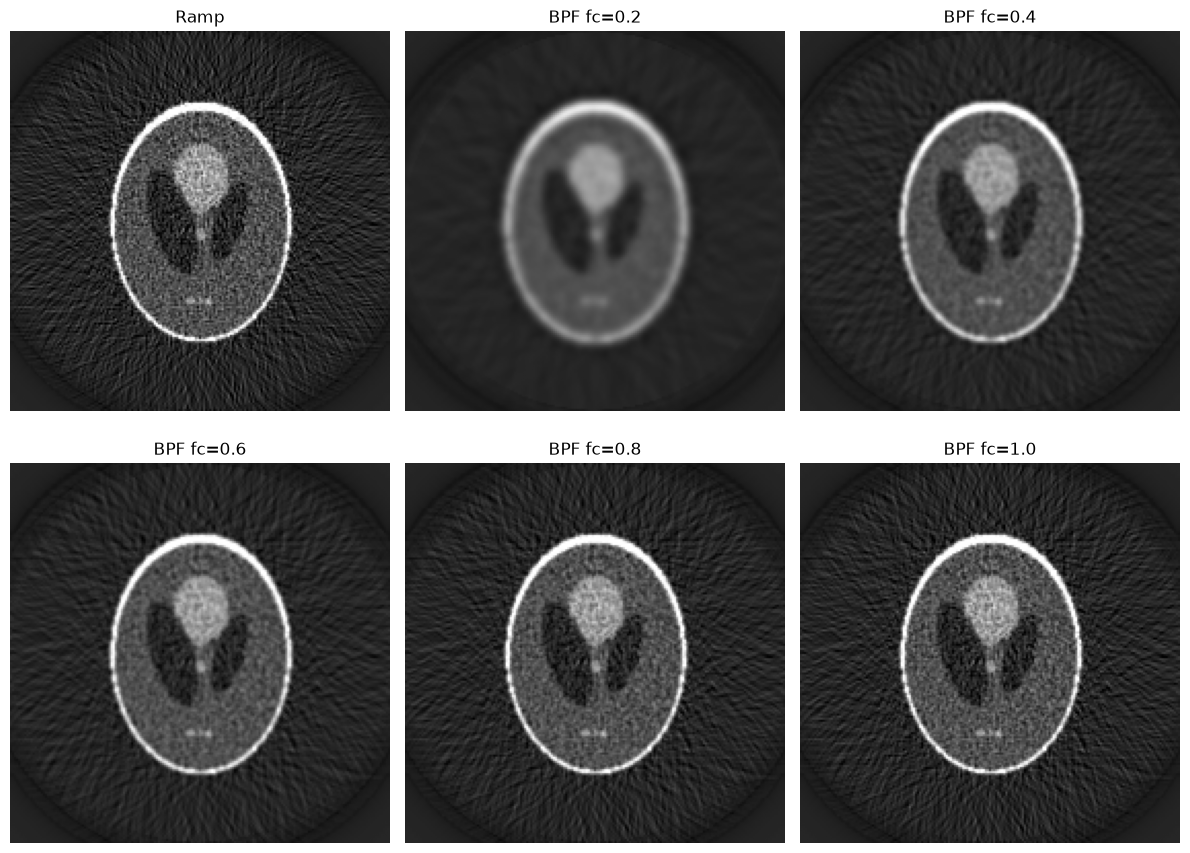

In [12]:

cutoff_ratios = [0.2, 0.4, 0.6, 0.8, 1.0]

images = [recon_ramp]
titles = ["Ramp"]

for ratio in cutoff_ratios:
    _, _, _, recon_bpf = reconstruct_fbp(
        sinogram,
        filter_type="BPF",
        cutoff_ratio=ratio,
        order=2
    )

    images.append(recon_bpf)
    titles.append(f"BPF fc={ratio}")

# 모든 영상에 동일한 밝기 범위 적용
vmin = min(np.percentile(img, 1) for img in images)
vmax = max(np.percentile(img, 99) for img in images)

fig, axes = plt.subplots(2, 3, figsize=(12, 9))

for ax, img, title in zip(axes.flat, images, titles):
    ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


## cutoff ratio를 0.4로 고정하고, Butterworth filter order n 비교

Number of projections (angles): 180
Number of detector bins:        185
Number of projections (angles): 180
Number of detector bins:        185
Number of projections (angles): 180
Number of detector bins:        185
Number of projections (angles): 180
Number of detector bins:        185


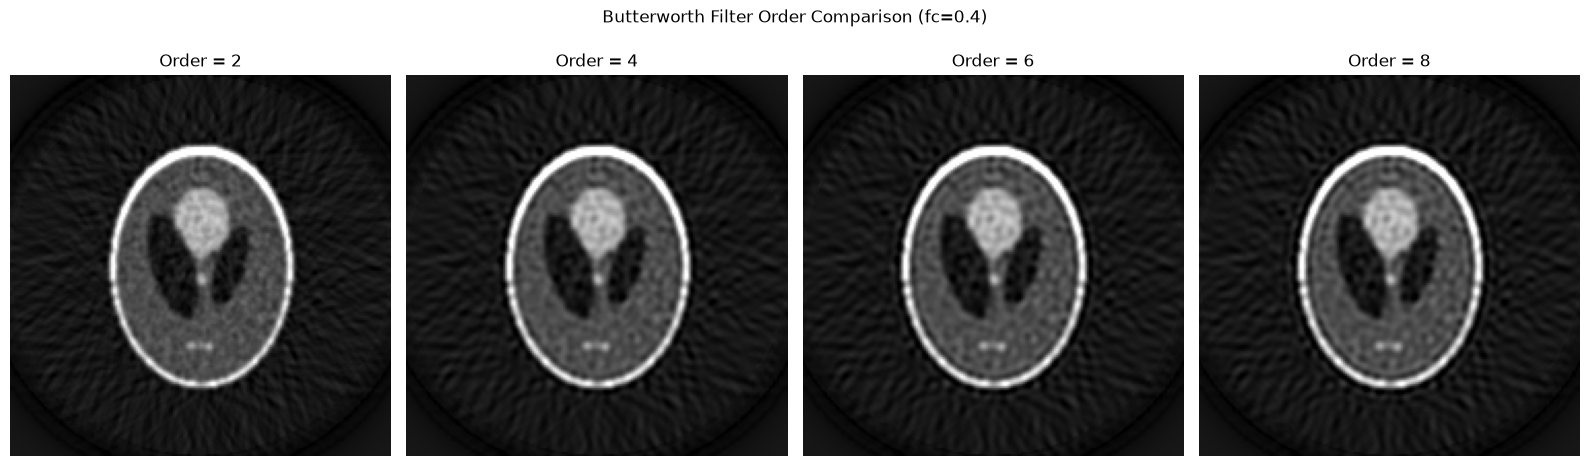

In [13]:

orders = [2, 4, 6, 8]
cutoff_ratio = 0.4

images = []

for order in orders:
    _, _, _, recon = reconstruct_fbp(
        sinogram,
        filter_type="BPF",
        cutoff_ratio=cutoff_ratio,
        order=order
    )
    images.append(recon)

# 동일한 밝기 범위로 비교
vmin = min(np.percentile(img, 1) for img in images)
vmax = max(np.percentile(img, 99) for img in images)

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, img, order in zip(axes, images, orders):
    ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(f"Order = {order}")
    ax.axis("off")

plt.suptitle("Butterworth Filter Order Comparison (fc=0.4)")
plt.tight_layout()
plt.show()


## 3. Resonstruct the images from the other sinograms (sinogram_highnoise.png and sinogram_lownoise.png). Try to find the best filter parameters for each case.

1. High-noise와 low-noise Sinogram을 각각 FBP로 복원하기

High-noise shape: (256, 256)
Low-noise shape: (256, 256)


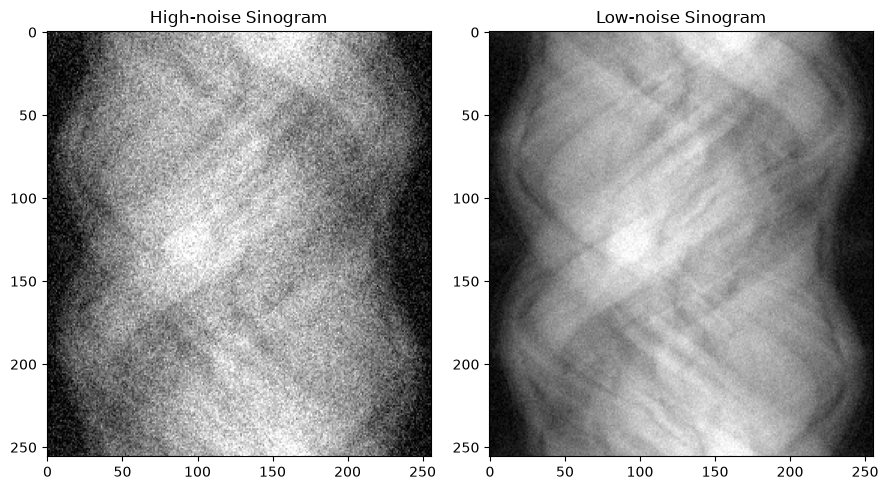

In [14]:

from skimage import io
import numpy as np
import matplotlib.pyplot as plt

# 두 Sinogram 불러오기
sinogram_high = np.asarray(
    io.imread("sinogram_highnoise.png"), dtype=float
)

sinogram_low = np.asarray(
    io.imread("sinogram_lownoise.png"), dtype=float
)

print("High-noise shape:", sinogram_high.shape)
print("Low-noise shape:", sinogram_low.shape)

# 원본 비교
fig, axes = plt.subplots(1, 2, figsize=(9, 5))

axes[0].imshow(sinogram_high, cmap="gray", aspect="auto")
axes[0].set_title("High-noise Sinogram")

axes[1].imshow(sinogram_low, cmap="gray", aspect="auto")
axes[1].set_title("Low-noise Sinogram")

plt.tight_layout()
plt.show()


Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256


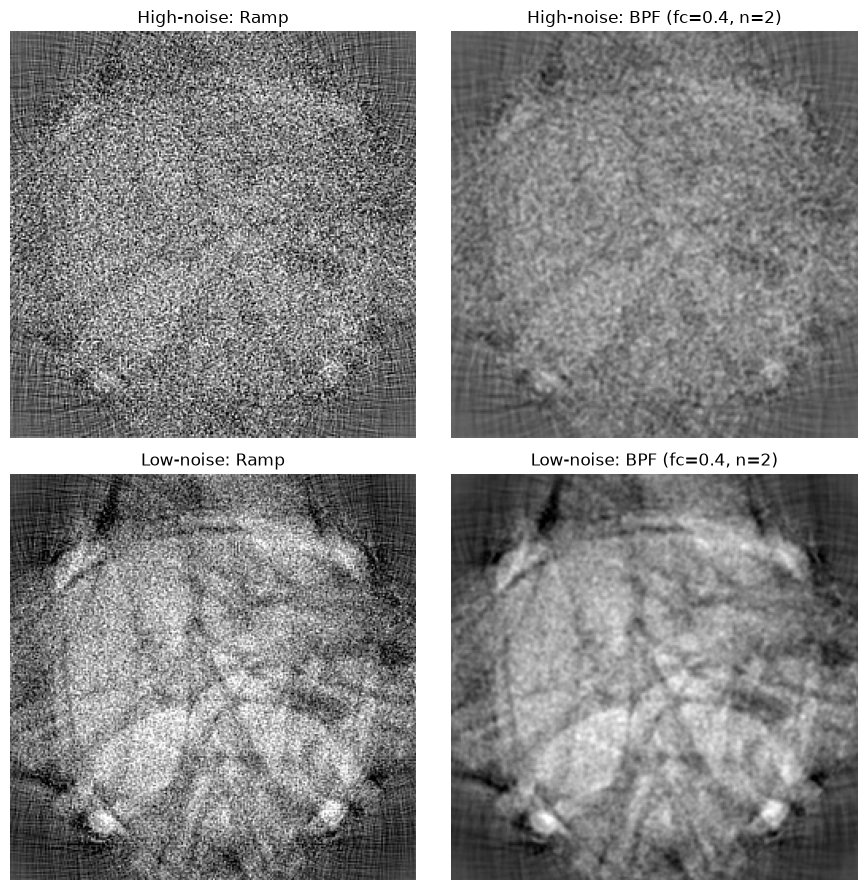

In [15]:

datasets = [
    ("High-noise", sinogram_high),
    ("Low-noise", sinogram_low)
]

fig, axes = plt.subplots(2, 2, figsize=(9, 9))

for row, (name, sino) in enumerate(datasets):

    # Ramp reconstruction
    _, _, _, recon_ramp = reconstruct_fbp(
        sino, filter_type="ramp"
    )

    # BPF reconstruction
    _, _, _, recon_bpf = reconstruct_fbp(
        sino,
        filter_type="BPF",
        cutoff_ratio=0.4,
        order=2
    )

    # 같은 데이터셋 내에서는 동일한 밝기 범위
    vmin = min(np.percentile(im, 1) for im in [recon_ramp, recon_bpf])
    vmax = max(np.percentile(im, 99) for im in [recon_ramp, recon_bpf])

    axes[row, 0].imshow(recon_ramp, cmap="gray", vmin=vmin, vmax=vmax)
    axes[row, 0].set_title(f"{name}: Ramp")

    axes[row, 1].imshow(recon_bpf, cmap="gray", vmin=vmin, vmax=vmax)
    axes[row, 1].set_title(f"{name}: BPF (fc=0.4, n=2)")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


2. 각 영상에서 cutoff frequency와 filter order를 조절하여 적절한 조합 찾기

order=2를 고정하고 cutoff를 0.1부터 0.8까지 바꿔보기

Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256


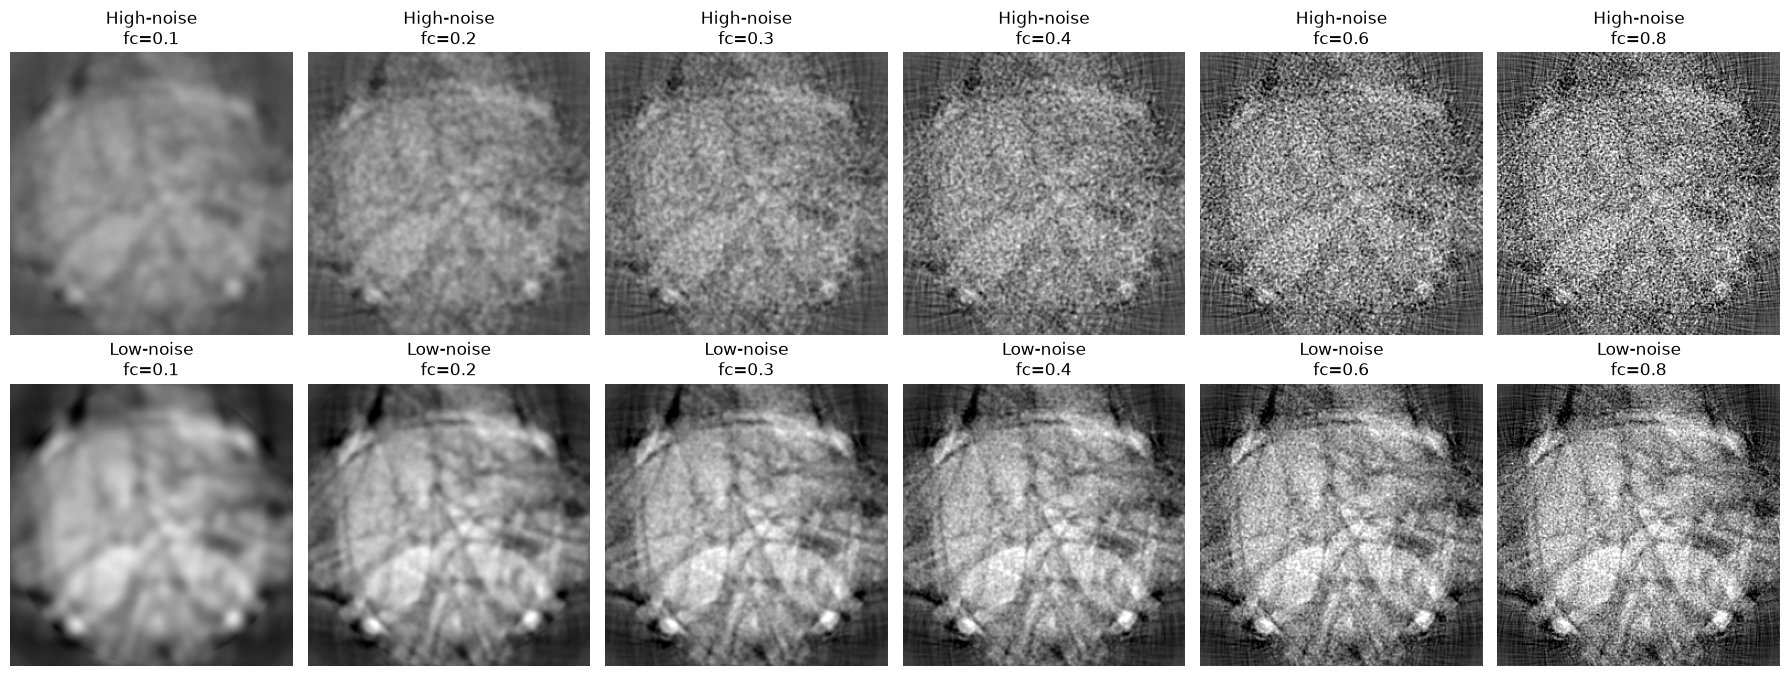

In [16]:

cutoff_ratios = [0.1, 0.2, 0.3, 0.4, 0.6, 0.8]

datasets = [
    ("High-noise", sinogram_high),
    ("Low-noise", sinogram_low)
]

fig, axes = plt.subplots(2, 6, figsize=(18, 7))

for row, (name, sino) in enumerate(datasets):

    reconstructions = []

    # Cutoff ratio별 복원
    for ratio in cutoff_ratios:
        _, _, _, recon = reconstruct_fbp(
            sino,
            filter_type="BPF",
            cutoff_ratio=ratio,
            order=2
        )
        reconstructions.append(recon)

    # 같은 데이터셋 내에서 동일한 밝기 범위 적용
    vmin = min(np.percentile(im, 1) for im in reconstructions)
    vmax = max(np.percentile(im, 99) for im in reconstructions)

    for col, (ratio, recon) in enumerate(
        zip(cutoff_ratios, reconstructions)
    ):
        axes[row, col].imshow(
            recon,
            cmap="gray",
            vmin=vmin,
            vmax=vmax
        )
        axes[row, col].set_title(
            f"{name}\nfc={ratio}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


이제 각 데이터셋에서 cutoff를 고정하고 n=2,4,6,8을 비교
- High-noise: fc=0.2
- Low-noise: fc=0.3

Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256
Number of projections (angles): 256
Number of detector bins:        256


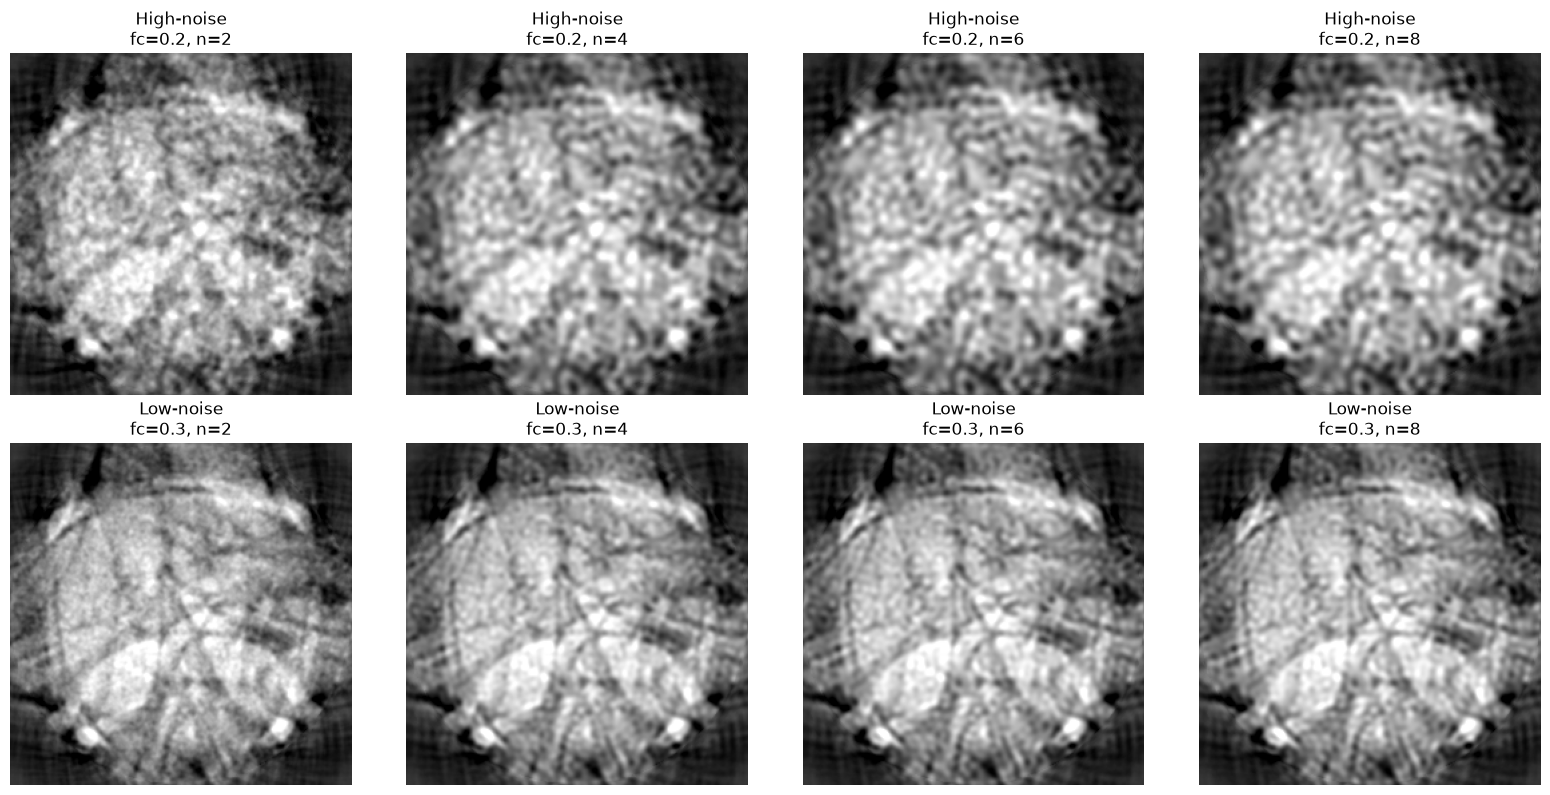

In [17]:

orders = [2, 4, 6, 8]

datasets = [
    ("High-noise", sinogram_high, 0.2),
    ("Low-noise", sinogram_low, 0.3)
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for row, (name, sino, cutoff) in enumerate(datasets):

    reconstructions = []

    for order in orders:
        _, _, _, recon = reconstruct_fbp(
            sino,
            filter_type="BPF",
            cutoff_ratio=cutoff,
            order=order
        )
        reconstructions.append(recon)

    # 같은 데이터셋에서는 동일한 밝기 범위
    vmin = min(np.percentile(im, 1) for im in reconstructions)
    vmax = max(np.percentile(im, 99) for im in reconstructions)

    for col, (order, recon) in enumerate(
        zip(orders, reconstructions)
    ):
        axes[row, col].imshow(
            recon,
            cmap="gray",
            vmin=vmin,
            vmax=vmax
        )

        axes[row, col].set_title(
            f"{name}\nfc={cutoff}, n={order}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


결과: 

High-noise

fc = 0.2, n = 2


Low-noise

fc = 0.3, n = 4 로 확정